# Week 1 — Per-head low-rank structure of K and V

**Question.** How compressible are the key and value states of each attention head, and is the
answer the same across languages?

**What this notebook does**

1. Runs a multilingual decoder-only model over an equal token budget per language.
2. Hooks `k_proj` / `v_proj` in every layer and accumulates second-moment (Gram) matrices.
   No raw K/V tensors are stored, so disk usage stays small.
3. Computes the singular-value spectrum per layer and per KV head, then derives the
   normalized effective rank (NER) and the rank needed to keep 90 / 95 / 99 % of the energy.
4. Plots layer x head maps and measures whether head-level compressibility agrees across languages.

**Kaggle settings.** Accelerator: GPU T4 (one is enough). Internet: On.

**Before spending GPU quota**, run once with `SMOKE_TEST = True` on CPU. It uses a tiny random
model and random tokens, and checks the whole pipeline in under a minute.

**Design choices to keep in mind when reading results**

- *KV heads, not query heads.* With grouped-query attention the cache holds `num_key_value_heads`
  heads per layer. That is the unit analysed here.
- *Keys are captured before RoPE.* This is the space where weight-factorisation methods
  (Palu-style) operate. The cached keys in most implementations are post-RoPE; that comparison is
  a possible Week 2 extension.
- *Uncentered second moments.* Eigenvalues of `X^T X` are the squared singular values of the data
  matrix, which is what a truncated-SVD projection sees.
- *Equal token budget per language.* The cache grows per token, so tokens (not words or
  sentences) are the fair unit. Languages the tokenizer splits more finely cover less text.
- *Wikipedia is not parallel.* Content differs across languages. Treat cross-language gaps as
  suggestive until they are replicated on a parallel corpus.

In [1]:
import os

# ---------------- configuration ----------------
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # set True for a CPU dry run

MODEL_ID = "Qwen/Qwen3-1.7B"        # any HF causal LM whose layers expose self_attn.k_proj / v_proj
LANGS = ["en", "es", "fi", "qu"]    # Wikipedia language codes
WIKI_SNAPSHOT = "20231101"          # wikimedia/wikipedia config prefix

SEQ_LEN = 512                # tokens per window
TOKENS_PER_LANG = 200_000    # equal token budget per language
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
BATCH_SIZE = 8
SKIP_FIRST_TOKENS = 1        # drop position 0: it tends to carry outlier norms that dominate spectra
ENERGY_LEVELS = (0.90, 0.95, 0.99)
SEED = 0

OUT_DIR = "/kaggle/working/kv_rank_week1" if os.path.isdir("/kaggle/working") else "./kv_rank_week1"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    LANGS = ["aa", "bb", "cc"]
    SEQ_LEN, TOKENS_PER_LANG, BATCH_SIZE = 64, 64 * 40, 8
print("SMOKE_TEST =", SMOKE_TEST, "| output ->", OUT_DIR)

SMOKE_TEST = False | output -> /kaggle/working/kv_rank_week1


In [2]:
import json, math, time, itertools
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

device: cpu | torch 2.11.0+cpu


## 1. Model

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

if SMOKE_TEST:
    from transformers import LlamaConfig, LlamaForCausalLM
    cfg = LlamaConfig(vocab_size=1000, hidden_size=64, intermediate_size=128, num_hidden_layers=3,
                      num_attention_heads=4, num_key_value_heads=2, max_position_embeddings=256)
    model = LlamaForCausalLM(cfg)
    tokenizer = None
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    half = torch.float16 if device == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=half)
    except TypeError:   # older transformers
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=half)

model.to(device).eval()
cfg = model.config
N_LAYERS = cfg.num_hidden_layers
N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
D_KV = N_KV * HEAD_DIM
print(f"layers={N_LAYERS}  query_heads={cfg.num_attention_heads}  kv_heads={N_KV}  "
      f"head_dim={HEAD_DIM}  kv_width={D_KV}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

layers=28  query_heads=16  kv_heads=8  head_dim=128  kv_width=1024


## 2. Data — equal token budget per language

Articles are streamed, tokenized, truncated to `MAX_TOKENS_PER_ARTICLE` (for topical diversity)
and cut into full windows of `SEQ_LEN` tokens. Every window is full, so no padding mask is needed.

In [4]:
def wiki_windows(lang):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    n_windows = TOKENS_PER_LANG // SEQ_LEN
    windows, n_articles = [], 0
    for row in ds:
        text = row["text"]
        if len(text) < MIN_CHARS_PER_ARTICLE:
            continue
        ids = tokenizer(text, add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        n_articles += 1
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            windows.append(ids[i:i + SEQ_LEN])
            if len(windows) == n_windows:
                return torch.tensor(windows), n_articles
    raise RuntimeError(f"{lang}: only {len(windows)} windows available, lower TOKENS_PER_LANG")


def smoke_windows(lang):
    # each fake language draws from a different slice of the vocabulary
    lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
    g = torch.Generator().manual_seed(SEED + lo)
    return torch.randint(lo, lo + 300, (TOKENS_PER_LANG // SEQ_LEN, SEQ_LEN), generator=g), 0


data = {}
for lang in LANGS:
    t0 = time.time()
    data[lang], n_art = (smoke_windows if SMOKE_TEST else wiki_windows)(lang)
    print(f"{lang}: {tuple(data[lang].shape)} windows x tokens from {n_art} articles ({time.time()-t0:.0f}s)")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

en: (390, 512) windows x tokens from 551 articles (11s)
es: (390, 512) windows x tokens from 477 articles (8s)
fi: (390, 512) windows x tokens from 497 articles (8s)
qu: (390, 512) windows x tokens from 964 articles (7s)


## 3. Gram collector

One accumulator per layer and per kind (K or V), of size `kv_width x kv_width`.
The per-head Gram matrices are its diagonal blocks, so a single pass gives both views:

- **per head**: what a head-wise projection can exploit;
- **per layer (joint)**: what a projection shared across heads can exploit, which also captures
  redundancy *between* heads.

In [5]:
class GramCollector:
    def __init__(self, model, skip_first=0):
        self.skip = skip_first
        self.handles = []
        self.gram = {"K": torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device),
                     "V": torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device)}
        self.n_tokens = 0
        found = {"K": {}, "V": {}}
        for name, mod in model.named_modules():
            for kind, suffix in (("K", "self_attn.k_proj"), ("V", "self_attn.v_proj")):
                if name.endswith(suffix):
                    found[kind][name] = mod
        for kind in ("K", "V"):
            mods = list(found[kind].values())
            assert len(mods) == N_LAYERS, f"expected {N_LAYERS} {kind} projections, found {len(mods)}"
            for layer, mod in enumerate(mods):   # named_modules preserves layer order
                assert mod.out_features == D_KV, (mod.out_features, D_KV)
                self.handles.append(mod.register_forward_hook(self._hook(kind, layer)))

    def _hook(self, kind, layer):
        def fn(mod, inputs, out):
            x = out[:, self.skip:, :].reshape(-1, out.shape[-1]).float()   # fp32: fp16 products overflow
            self.gram[kind][layer] += (x.T @ x).double()
            if kind == "K" and layer == 0:
                self.n_tokens += x.shape[0]
        return fn

    def reset(self):
        for g in self.gram.values():
            g.zero_()
        self.n_tokens = 0

    def close(self):
        for h in self.handles:
            h.remove()


@torch.no_grad()
def run_language(windows, collector):
    collector.reset()
    total_loss, total_tok = 0.0, 0
    for i in range(0, len(windows), BATCH_SIZE):
        ids = windows[i:i + BATCH_SIZE].to(device)
        out = model(input_ids=ids, labels=ids, use_cache=False)
        n = ids.shape[0] * (ids.shape[1] - 1)
        total_loss += out.loss.float().item() * n
        total_tok += n
    return math.exp(total_loss / total_tok)

In [6]:
collector = GramCollector(model, skip_first=SKIP_FIRST_TOKENS)
grams, baseline_ppl = {}, {}
for lang in LANGS:
    t0 = time.time()
    baseline_ppl[lang] = run_language(data[lang], collector)
    grams[lang] = {k: (g / collector.n_tokens).cpu().numpy() for k, g in collector.gram.items()}
    np.savez_compressed(os.path.join(OUT_DIR, f"gram_{lang}.npz"),
                        K=grams[lang]["K"].astype(np.float32), V=grams[lang]["V"].astype(np.float32),
                        n_tokens=collector.n_tokens)
    print(f"{lang}: ppl={baseline_ppl[lang]:.2f}  tokens={collector.n_tokens}  ({time.time()-t0:.0f}s)")
collector.close()
with open(os.path.join(OUT_DIR, "baseline_ppl.json"), "w") as f:
    json.dump(baseline_ppl, f, indent=2)

en: ppl=15.88  tokens=199290  (7532s)
es: ppl=13.21  tokens=199290  (7539s)
fi: ppl=15.47  tokens=199290  (7349s)
qu: ppl=37.15  tokens=199290  (7392s)


## 4. Spectra and rank metrics

For a spectrum of singular values $\sigma_1 \ge \dots \ge \sigma_d$:

- **Effective rank** $= \exp\big(-\sum_i p_i \log p_i\big)$ with $p_i = \sigma_i / \sum_j \sigma_j$.
- **NER** $=$ effective rank $/\, d$, in $(0, 1]$. Lower means more compressible.
- **$r_{\alpha}$**: smallest rank that keeps a fraction $\alpha$ of the energy $\sum_i \sigma_i^2$,
  reported as a fraction of $d$. This is the number a truncation method actually needs.

NER follows the idea used in KV-CoRE; check their exact definition before comparing numbers directly.

In [7]:
def spectrum_metrics(gram):
    lam = np.clip(np.linalg.eigvalsh(gram)[::-1], 0.0, None)   # descending, squared singular values
    s = np.sqrt(lam)
    p = s / s.sum()
    p = p[p > 0]
    erank = float(np.exp(-(p * np.log(p)).sum()))
    energy = np.cumsum(lam) / lam.sum()
    d = len(lam)
    m = {"dim": d, "erank": erank, "ner": erank / d, "top1_energy": float(lam[0] / lam.sum())}
    for a in ENERGY_LEVELS:
        m[f"r{int(a*100)}_frac"] = float((np.searchsorted(energy, a) + 1) / d)
    return m, lam


rows, spectra = [], {}
for lang, kind, layer in itertools.product(LANGS, ("K", "V"), range(N_LAYERS)):
    G = grams[lang][kind][layer]
    m, lam = spectrum_metrics(G)                                   # joint: all KV heads of the layer
    rows.append({"lang": lang, "kind": kind, "layer": layer, "head": -1, "scope": "layer", **m})
    spectra[f"{lang}/{kind}/L{layer}/joint"] = lam.astype(np.float32)
    for h in range(N_KV):
        sl = slice(h * HEAD_DIM, (h + 1) * HEAD_DIM)
        m, lam = spectrum_metrics(G[sl, sl])
        rows.append({"lang": lang, "kind": kind, "layer": layer, "head": h, "scope": "head", **m})
        spectra[f"{lang}/{kind}/L{layer}/H{h}"] = lam.astype(np.float32)

df = pd.DataFrame(rows)
df.to_csv(os.path.join(OUT_DIR, "rank_metrics.csv"), index=False)
np.savez_compressed(os.path.join(OUT_DIR, "spectra.npz"), **spectra)
heads = df[df.scope == "head"]
print(heads.groupby(["lang", "kind"])[["ner", "r90_frac", "r95_frac", "r99_frac"]].mean().round(3))

             ner  r90_frac  r95_frac  r99_frac
lang kind                                     
en   K     0.642     0.246     0.420     0.741
     V     0.907     0.701     0.830     0.961
es   K     0.643     0.248     0.421     0.741
     V     0.902     0.691     0.824     0.959
fi   K     0.637     0.240     0.408     0.732
     V     0.881     0.650     0.796     0.951
qu   K     0.611     0.207     0.368     0.705
     V     0.863     0.617     0.771     0.944


## 5. Plots

**How to read them**

- *Keys vs values by depth*: if the K curve sits below the V curve, keys are more compressible,
  and a method should give them a smaller rank.
- *Layer x head maps*: uniform rows mean a per-layer rank is enough; mixed rows mean per-head
  rank allocation has something to gain.
- *Joint vs per-head*: a joint NER well below the mean per-head NER means heads in that layer
  overlap, so a shared projection beats independent per-head projections.

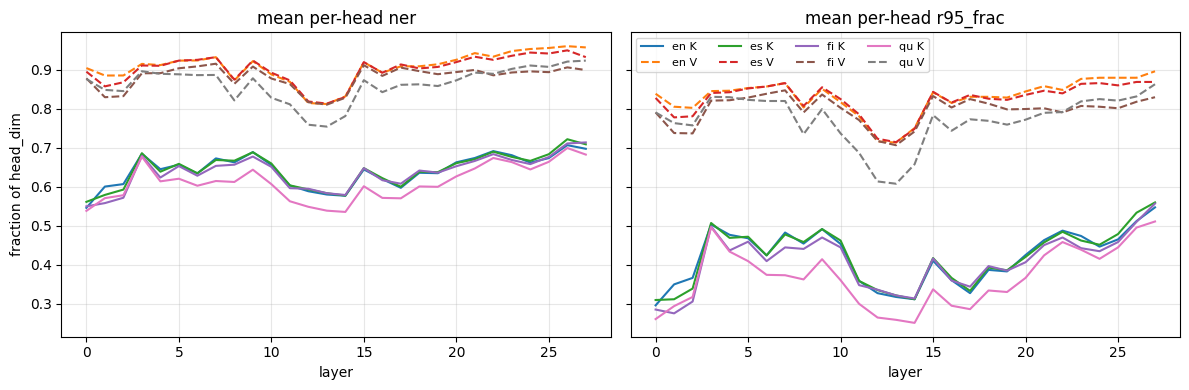

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, metric in zip(axes, ("ner", "r95_frac")):
    for lang in LANGS:
        for kind, ls in (("K", "-"), ("V", "--")):
            y = heads[(heads.lang == lang) & (heads.kind == kind)].groupby("layer")[metric].mean()
            ax.plot(y.index, y.values, ls, label=f"{lang} {kind}")
    ax.set_xlabel("layer"); ax.set_title(f"mean per-head {metric}"); ax.grid(alpha=.3)
axes[0].set_ylabel("fraction of head_dim"); axes[1].legend(ncol=len(LANGS), fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "k_vs_v_by_depth.png"), dpi=150); plt.show()

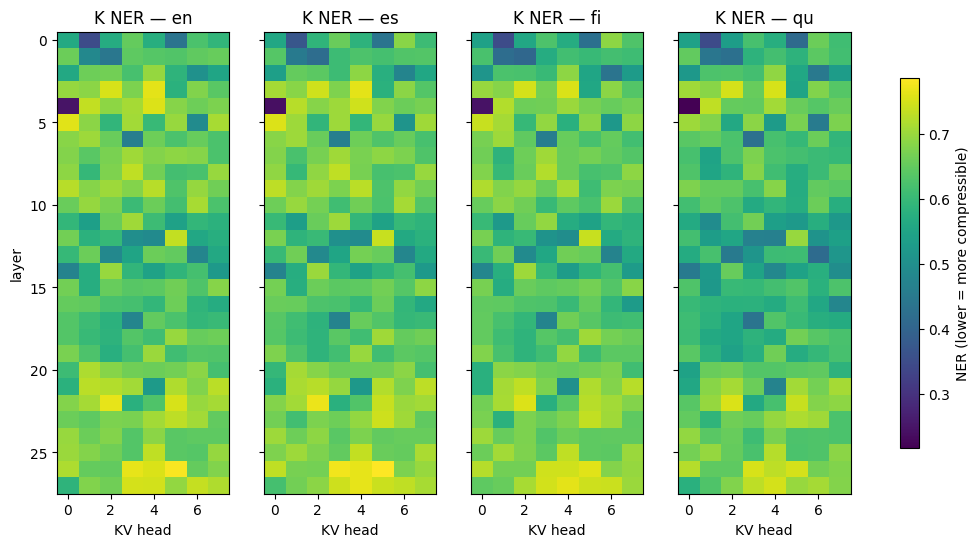

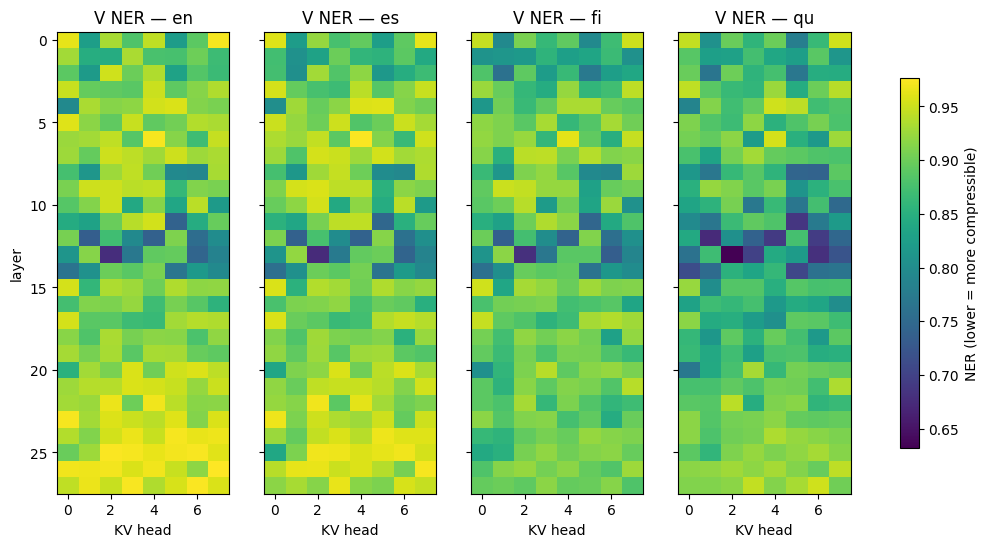

In [9]:
def head_map(lang, kind, metric="ner"):
    sub = heads[(heads.lang == lang) & (heads.kind == kind)]
    return sub.pivot(index="layer", columns="head", values=metric).values

for kind in ("K", "V"):
    maps = {lang: head_map(lang, kind) for lang in LANGS}
    vmin = min(m.min() for m in maps.values()); vmax = max(m.max() for m in maps.values())
    fig, axes = plt.subplots(1, len(LANGS), figsize=(3.2 * len(LANGS), 6), sharey=True, squeeze=False)
    for ax, lang in zip(axes[0], LANGS):
        im = ax.imshow(maps[lang], aspect="auto", vmin=vmin, vmax=vmax, cmap="viridis")
        ax.set_title(f"{kind} NER — {lang}"); ax.set_xlabel("KV head")
    axes[0][0].set_ylabel("layer")
    fig.colorbar(im, ax=axes[0].tolist(), shrink=.8, label="NER (lower = more compressible)")
    plt.savefig(os.path.join(OUT_DIR, f"head_map_{kind}.png"), dpi=150, bbox_inches="tight"); plt.show()

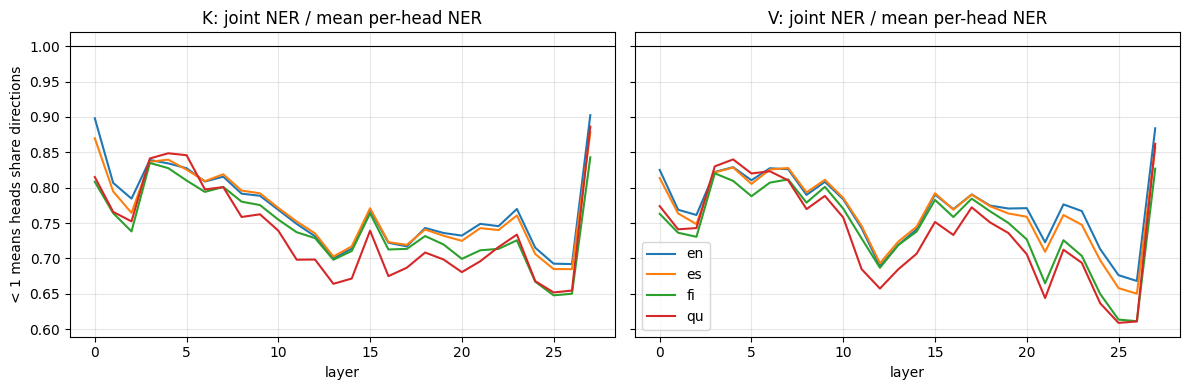

In [10]:
layer_df = df[df.scope == "layer"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, kind in zip(axes, ("K", "V")):
    for lang in LANGS:
        joint = layer_df[(layer_df.lang == lang) & (layer_df.kind == kind)].set_index("layer")["ner"]
        per_head = heads[(heads.lang == lang) & (heads.kind == kind)].groupby("layer")["ner"].mean()
        ax.plot(joint.index, (joint / per_head).values, label=lang)
    ax.axhline(1.0, color="k", lw=.8); ax.set_title(f"{kind}: joint NER / mean per-head NER")
    ax.set_xlabel("layer"); ax.grid(alpha=.3)
axes[0].set_ylabel("< 1 means heads share directions"); axes[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "joint_vs_per_head.png"), dpi=150); plt.show()

## 6. Do languages agree on which heads are compressible?

Spearman correlation of per-head NER between language pairs, computed two ways:

- **raw**: over all (layer, head) cells. This is inflated by the depth trend every language shares.
- **within-layer**: after subtracting each layer's mean. This isolates whether the *same heads
  inside a layer* are the compressible ones, which is the question that matters for
  language-specific rank allocation.

A high raw value with a low within-layer value means languages agree on *which layers* compress
well but not on *which heads*.

In [11]:
def spearman(a, b):
    return float(pd.Series(a).rank().corr(pd.Series(b).rank()))

agree = []
for kind in ("K", "V"):
    maps = {lang: head_map(lang, kind) for lang in LANGS}
    for a, b in itertools.combinations(LANGS, 2):
        raw = spearman(maps[a].ravel(), maps[b].ravel())
        wa = maps[a] - maps[a].mean(axis=1, keepdims=True)
        wb = maps[b] - maps[b].mean(axis=1, keepdims=True)
        agree.append({"kind": kind, "pair": f"{a}-{b}", "spearman_raw": raw,
                      "spearman_within_layer": spearman(wa.ravel(), wb.ravel()),
                      "mean_abs_ner_gap": float(np.abs(maps[a] - maps[b]).mean())})
agree = pd.DataFrame(agree)
agree.to_csv(os.path.join(OUT_DIR, "cross_language_agreement.csv"), index=False)
agree.round(3)

,kind,pair,spearman_raw,spearman_within_layer,mean_abs_ner_gap
0,K,en-es,0.981,0.986,0.007
1,K,en-fi,0.948,0.960,0.014
2,K,en-qu,0.940,0.958,0.032
3,K,es-fi,0.981,0.982,0.010
4,K,es-qu,0.950,0.963,0.033
5,K,fi-qu,0.953,0.977,0.029
6,V,en-es,0.955,0.971,0.008
7,V,en-fi,0.796,0.920,0.027
8,V,en-qu,0.924,0.929,0.044
9,V,es-fi,0.896,0.953,0.022


## 7. What to take into Week 2

Week 1 is correlational: it says where the spectrum is concentrated, not which directions the
model needs. Week 2 intervenes:

1. Build a rank-`r` projection per head from the top eigenvectors of the saved Gram matrices
   (`gram_<lang>.npz`) and apply it inside the forward pass.
2. Measure perplexity against `baseline_ppl.json`, plus one downstream task.
3. Cross the bases: project language B with the basis fitted on language A. The gap to the
   matched basis is the calibration-language effect, measured head by head.

Checks worth doing before trusting the Week 1 numbers:

- Re-run with a different `SEED` and with half the token budget. The maps should be stable.
- Set `SKIP_FIRST_TOKENS = 0` once to see how much position 0 alone shifts the spectra.
- Replace Wikipedia with a parallel corpus to separate language from content.